# Sampling k from N

The problem is how to sample k options from N, given logits for each of the N options. This is a common problem in reinforcement learning when we want to sample multiple actions from a categorical distribution, or in combinatorial optimisation when we want to sample subsets of items.

In [199]:
from collections.abc import Callable
from itertools import product

import torch

In [200]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Setup

We set up random logits for a batch of B instances, with R rollouts per each, and N options to choose from. We will sample k options from these N for each rollout.

In [201]:
B, R, N = 64, 128, 20
k = 5

logits = torch.rand(B, R, N)
print(logits[0, 0])

tensor([0.0115, 0.6648, 0.9133, 0.1340, 0.5021, 0.3748, 0.8665, 0.7983, 0.7002,
        0.2173, 0.8729, 0.8227, 0.6668, 0.1607, 0.7102, 0.9177, 0.1927, 0.4281,
        0.9356, 0.9711])


## Log-probability from subsequent sampled actions

Log-probability is required for REINFORCE. It needs to be differentiable w.r.t. the logits. However, it doesn't need to be differentiable w.r.t. the selected indices.

In [202]:
import torch.nn.functional as F


def log_prob_of_sequence_without_replacement(
    logits: torch.Tensor, selected: torch.Tensor
) -> torch.Tensor:
    """
    Args:
        logits: (B, R, N)
        selected: (B, R, k)

    Returns:
        log_p: (B, R) log-probability of the selected sequence.
    """
    B, R, N = logits.shape
    k = selected.shape[-1]
    log_p = torch.zeros(B, R, device=logits.device)
    mask = torch.zeros(B, R, N, dtype=torch.bool, device=logits.device)

    for k_idx in range(k):
        masked_logits = logits.masked_fill(mask, float("-inf"))
        log_p += (
            F.log_softmax(masked_logits, dim=-1)
            .gather(-1, selected[..., k_idx : k_idx + 1])
            .squeeze(-1)
        )
        mask = mask.scatter(-1, selected[..., k_idx : k_idx + 1], True)

    return log_p

## Sampling

Different methods for sampling k from N.

### Categorical

In [203]:
selected = torch.zeros((B, R, k), dtype=torch.long)
mask = torch.zeros((B, R, N), dtype=torch.bool)
for k_idx in range(k):
    masked_logits = logits.masked_fill(mask, float("-inf"))
    distribution = torch.distributions.Categorical(logits=masked_logits)
    selected[:, :, k_idx] = distribution.sample()
    mask.scatter_(-1, selected[:, :, k_idx : k_idx + 1], True)
print(selected.shape)
print(selected[0, 0])
print(selected[0, 1])

for b, r in product(range(B), range(R)):
    assert len(set(selected[b, r].tolist())) == k, "Duplicate selection detected!"

log_p = log_prob_of_sequence_without_replacement(logits, selected)
print(log_p.shape)  # (B, R)
print(log_p[0, 0])
print(torch.exp(log_p[0, 0]))

torch.Size([64, 128, 5])
tensor([ 3, 11,  5,  2, 17])
tensor([11, 18, 13,  3, 17])
torch.Size([64, 128])
tensor(-15.0115)
tensor(3.0240e-07)


### Multinomial without replacement

In [204]:
selected = torch.multinomial(logits.softmax(-1).view(-1, N), num_samples=k, replacement=False).view(
    B, R, k
)
print(selected.shape)
print(selected[0, 0])
print(selected[0, 1])

for b, r in product(range(B), range(R)):
    assert len(set(selected[b, r].tolist())) == k, "Duplicate selection detected!"

log_p = log_prob_of_sequence_without_replacement(logits, selected)
print(log_p.shape)  # (B, R)
print(log_p[0, 0])
print(torch.exp(log_p[0, 0]))

torch.Size([64, 128, 5])
tensor([15,  8,  0,  1, 18])
tensor([ 5,  4,  6, 19, 14])
torch.Size([64, 128])
tensor(-14.3610)
tensor(5.7958e-07)


### Gumbel

**Variant 1**: Manual

In [205]:
gumbel = -torch.log(-torch.log(torch.rand_like(logits) + 1e-10))
print(gumbel.shape)
print(gumbel[0, 0])

selected = (logits + gumbel).topk(k, dim=-1).indices  # (B, R, k)
print(selected.shape)
print(selected[0, 0])
print(selected[0, 1])

for b, r in product(range(B), range(R)):
    assert len(set(selected[b, r].tolist())) == k, "Duplicate selection detected!"

log_p = log_prob_of_sequence_without_replacement(logits, selected)
print(log_p.shape)  # (B, R)
print(log_p[0, 0])
print(torch.exp(log_p[0, 0]))

torch.Size([64, 128, 20])
tensor([-0.6029,  2.8842,  1.4701,  0.0933, -0.3422,  0.1080, -0.5407,  1.7011,
         2.5902,  2.6787,  1.2877,  1.4269,  0.4600,  0.0153,  1.7867,  0.4922,
        -0.4718,  0.9492,  0.3427,  2.4017])
torch.Size([64, 128, 5])
tensor([ 1, 19,  8,  9,  7])
tensor([19, 14,  1,  0, 16])
torch.Size([64, 128])
tensor(-14.2068)
tensor(6.7621e-07)


**Variant 2**: With `torch.distributions`

In [206]:
m = torch.distributions.gumbel.Gumbel(torch.zeros_like(logits), torch.ones_like(logits))
gumbel = m.sample()
print(gumbel.shape)
print(gumbel[0, 0])

selected = (logits + gumbel).topk(k, dim=-1).indices  # (B, R, k)
print(selected.shape)
print(selected[0, 0])
print(selected[0, 1])

for b, r in product(range(B), range(R)):
    assert len(set(selected[b, r].tolist())) == k, "Duplicate selection detected!"

log_p = log_prob_of_sequence_without_replacement(logits, selected)
print(log_p.shape)  # (B, R)
print(log_p[0, 0])
print(torch.exp(log_p[0, 0]))

torch.Size([64, 128, 20])
tensor([ 0.0699,  1.9535,  1.0066, -0.0719, -1.6525,  0.3878, -0.2905,  0.7848,
         1.1213,  1.9327,  0.5639, -0.7642, -0.0096, -0.2700, -0.6054,  0.6377,
         0.1085,  1.9017,  0.2199,  0.5667])
torch.Size([64, 128, 5])
tensor([ 1, 17,  9,  2,  8])
tensor([ 4,  6, 14,  3,  8])
torch.Size([64, 128])
tensor(-14.7467)
tensor(3.9410e-07)


### Slots

In [207]:
def make_demo_slot_logits(
    logits: torch.Tensor,
    k: int,
    generator: torch.Generator | None = None,
) -> torch.Tensor:
    """Expand (..., N) logits to (..., k, N) with per-slot perturbation.

    Args:
        logits: (..., N) base logits.
        k: number of slots.
        generator: optional RNG for reproducibility.

    Returns:
        (..., k, N) per-slot logits.
    """
    shape = (*logits.shape[:-1], k, logits.shape[-1])
    noise = torch.randn(shape, generator=generator, dtype=logits.dtype, device=logits.device)
    return logits.unsqueeze(-2) + noise  # (..., 1, N) broadcasts with (..., k, N)

In [208]:
def log_prob_of_slots_v1(logits_per_slot: torch.Tensor, selected: torch.Tensor) -> torch.Tensor:
    """
    Args:
        logits_per_slot: (B, R, k, N) per-slot logits.
        selected: (B, R, k) selected indices.

    Returns:
        log_p: (B, R) log-probability of the selected indices under the per-slot logits.
    """
    distribution = torch.distributions.Categorical(logits=logits_per_slot)
    log_p = distribution.log_prob(selected)  # (B, R, k)
    # Sum log-probs across slots to get total log-probability
    return log_p.sum(dim=-1)


def log_prob_of_slots_v2(
    logits: torch.Tensor,
    selected: torch.Tensor,
) -> torch.Tensor:
    log_p = logits.log_softmax(dim=-1)  # (..., k, N)
    return log_p.gather(-1, selected.unsqueeze(-1)).squeeze(-1).sum(dim=-1)


def log_prob_of_slots_wrong(
    logits: torch.Tensor,
    selected: torch.Tensor,
) -> torch.Tensor:
    return logits.gather(-1, selected.unsqueeze(-1)).squeeze(-1).sum(dim=-1)


logits_per_slot = make_demo_slot_logits(logits, k)
assert torch.allclose(
    log_prob_of_slots_v1(logits_per_slot, selected),
    log_prob_of_slots_v2(logits_per_slot, selected),
    atol=1e-6,
)
assert not torch.allclose(
    log_prob_of_slots_v1(logits_per_slot, selected),
    log_prob_of_slots_wrong(logits_per_slot, selected),
    atol=1e-6,
)

In [209]:
logits_per_slot = make_demo_slot_logits(logits, k)
print(logits_per_slot.shape)  # (B, R, k, N)
print(logits_per_slot[0, 0, 0])  # Slot 0
print(logits_per_slot[0, 0, 1])  # Slot 1

torch.Size([64, 128, 5, 20])
tensor([ 0.8318,  0.4051, -1.0163,  1.3382, -1.1385,  0.0462,  1.8864,  0.5445,
         0.8805, -0.0686,  1.6721,  0.8999, -0.9774,  1.4185,  0.5100,  1.6324,
         1.0571,  1.8927, -0.0583,  1.5994])
tensor([-0.2822,  1.8093,  2.1509,  1.7040,  0.7626, -0.8069,  2.6914,  0.1781,
         1.1895,  1.3889,  1.5752,  2.2607, -0.8980, -0.0930,  0.6986,  0.7658,
         0.0868,  0.2214, -0.7024,  1.5950])


In [210]:
distribution = torch.distributions.Categorical(logits=logits_per_slot)
selected = distribution.sample()  # (B, R, k)
print(selected.shape)
print(selected[0, 0])

torch.Size([64, 128, 5])
tensor([11,  6,  1,  0,  4])


## Sampling functions

In [211]:
def sample_gumbel_manual(
    logits: torch.Tensor, k: int, generator: torch.Generator | None = None
) -> torch.Tensor:
    with torch.no_grad():
        u = torch.rand(
            logits.shape, generator=generator, dtype=logits.dtype, device=logits.device
        ).clamp(min=torch.finfo(logits.dtype).tiny)
        gumbel = -torch.log(-torch.log(u))  # Gumbel(0, 1)
        return (logits + gumbel).topk(k, dim=-1).indices


def sample_gumbel_distributions(
    logits: torch.Tensor,
    k: int,
) -> torch.Tensor:
    with torch.no_grad():
        gumbel = torch.distributions.Gumbel(
            torch.zeros_like(logits), torch.ones_like(logits)
        ).sample()
        return (logits + gumbel).topk(k, dim=-1).indices

In [212]:
def sample_multinomial(
    logits: torch.Tensor, k: int, generator: torch.Generator | None = None
) -> torch.Tensor:
    with torch.no_grad():
        probs = logits.softmax(dim=-1)
        flat = probs.view(-1, logits.shape[-1])
        selected = torch.multinomial(flat, num_samples=k, replacement=False, generator=generator)
        return selected.view(*logits.shape[:-1], k)


def sample_multinomial_raw(
    logits: torch.Tensor, k: int, generator: torch.Generator | None = None
) -> torch.Tensor:
    """
    For demonstration. Wrong way to sample from multinomial. Probabilities, not raw logits are right.
    """
    with torch.no_grad():
        flat = logits.view(-1, logits.shape[-1])
        selected = torch.multinomial(flat, num_samples=k, replacement=False, generator=generator)
        return selected.view(*logits.shape[:-1], k)


def sample_k_categorical(
    logits: torch.Tensor,
    k: int,
) -> torch.Tensor:
    """Sample k nodes without replacement using masked Categorical.
    Alternative to sample_multinomial via torch.distributions.

    Args:
        logits: (..., N) logits.
        k: number of nodes to sample.

    Returns:
        (..., k) selected indices.
    """
    mask = torch.zeros_like(logits, dtype=torch.bool)
    indices = []
    for _ in range(k):
        idx = torch.distributions.Categorical(
            logits=logits.masked_fill(mask, float("-inf"))
        ).sample()  # (...,)
        indices.append(idx)
        mask.scatter_(-1, idx.unsqueeze(-1), True)
    return torch.stack(indices, dim=-1)  # (..., k)

In [213]:
def sample_k_slots(
    logits: torch.Tensor,
    generator: torch.Generator | None = None,
) -> torch.Tensor:
    """Sample k nodes using k independent slot queries over shared logits.

    Each slot independently samples one node by adding its own Gumbel noise,
    simulating k learned query vectors attending to the same node embeddings.
    Unlike Gumbel-top-k, slots sample with replacement. Duplicates can occur.

    Args:
        logits: (..., k, N) per-slot logits.
        generator: optional RNG for reproducibility.

    Returns:
        (..., k) selected indices, one per slot. May contain duplicates.
    """
    u = torch.rand(
        logits.shape, generator=generator, dtype=logits.dtype, device=logits.device
    ).clamp(min=torch.finfo(logits.dtype).tiny)
    gumbel = -torch.log(-torch.log(u))
    return (logits + gumbel).argmax(dim=-1)  # (..., k)


def sample_k_slots_categorical(
    logits: torch.Tensor,
) -> torch.Tensor:
    """Sample one node per slot using Categorical distribution.
    Equivalent to sample_k_slots but via torch.distributions.

    Args:
        logits: (..., k, N) per-slot logits.

    Returns:
        (..., k) selected indices, one per slot. May contain duplicates.
    """
    return torch.distributions.Categorical(logits=logits).sample()  # (..., k)

## Marginal distributions

For each method, we estimate the marginal selection probability P(node i is selected) empirically
over many samples from a single fixed instance. Gumbel-top-k and multinomial-softmax should converge
to the same marginals, while multinomial-raw will differ since it
treats logit values directly as weights rather than log-probabilities.

In [214]:
N_SAMPLES = 50_000

single_logits = logits[0, 0]  # (N,) - fixed instance for analysis
repeated_logits = single_logits.unsqueeze(0).expand(N_SAMPLES, -1)  # (N_SAMPLES, N)

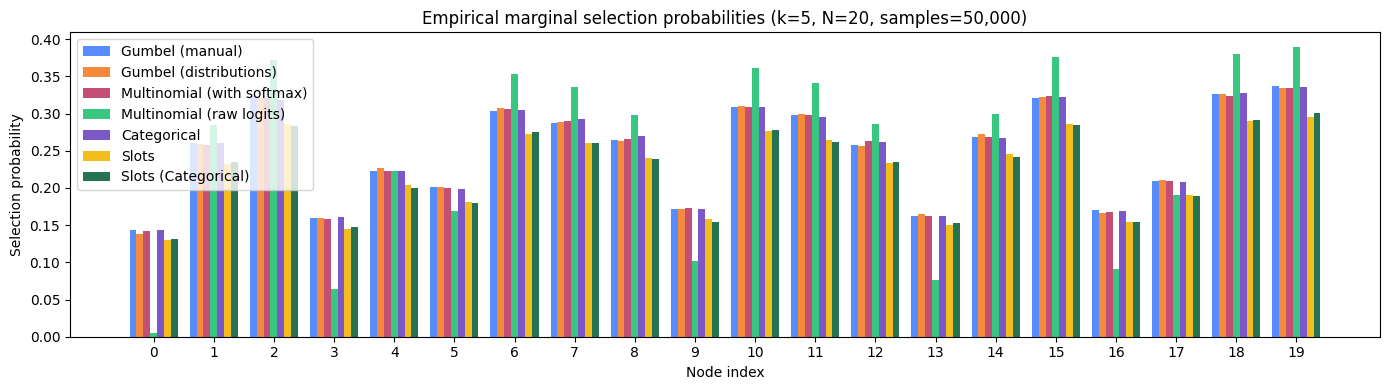

In [215]:
import matplotlib.pyplot as plt


def empirical_marginals(logits_2d: torch.Tensor, sample_fn: Callable, k: int) -> torch.Tensor:
    """Estimate marginal selection probability for each node via Monte Carlo.

    Args:
        logits_2d: (n_samples, N) logits repeated across sample dimension.
        sample_fn: callable(logits, k) -> (n_samples, k) selected indices.
        k: number of items selected per sample.

    Returns:
        (N,) empirical selection probabilities, one per node.
    """
    N = logits_2d.shape[-1]
    n_samples = logits_2d.shape[0]
    selected = sample_fn(logits_2d, k)  # (n_samples, k)
    counts = torch.zeros(N)
    for i in range(N):
        counts[i] = (selected == i).any(dim=-1).float().sum()
    return counts / n_samples


methods = [
    ("Gumbel (manual)", sample_gumbel_manual),
    ("Gumbel (distributions)", sample_gumbel_distributions),
    ("Multinomial (with softmax)", sample_multinomial),
    ("Multinomial (raw logits)", sample_multinomial_raw),
    ("Categorical", sample_k_categorical),
    ("Slots", lambda logits, k: sample_k_slots(make_demo_slot_logits(logits, k))),
    (
        "Slots (Categorical)",
        lambda logits, k: sample_k_slots_categorical(make_demo_slot_logits(logits, k)),
    ),
]

marginals = {name: empirical_marginals(repeated_logits, fn, k) for name, fn in methods}

fig, ax = plt.subplots(figsize=(14, 4))
x = torch.arange(N)
width = 0.8 / len(methods)
offsets = torch.linspace(
    -width * (len(methods) - 1) / 2, width * (len(methods) - 1) / 2, len(methods)
)

for (name, _), offset in zip(methods, offsets):
    ax.bar(x + offset, marginals[name], width, label=name)

ax.set_xlabel("Node index")
ax.set_ylabel("Selection probability")
ax.set_title(f"Empirical marginal selection probabilities (k={k}, N={N}, samples={N_SAMPLES:,})")
ax.legend()
ax.set_xticks([i for i in range(N)])
plt.tight_layout()
plt.show()

We can observe that multinomial with raw logits deviates significantly from the others. This is because it treats the logits as unnormalised weights rather than log-probabilities, leading to a different sampling distribution.

The other methods, including both Gumbel variants, multinomial with softmax, and categorical, all converge to the same marginals as expected since they sample from the same underlying distribution.

The slots methods also shows similar marginals with slight differences. It is caused by presence of duplicates what we analyse next.

## Duplicates when sampling with slots

In [216]:
def selection_stats(selected: torch.Tensor) -> dict:
    """Compute duplicate statistics over a batch of selections.

    Args:
        selected: (n_samples, k) selected indices.

    Returns:
        Dict with:
            has_duplicates: fraction of samples with at least one duplicate.
            mean_duplicates: average number of duplicate entries per sample.
            duplicate_ratio: mean_duplicates / k, fraction of slots wasted to duplicates.
    """
    k = selected.shape[-1]
    num_unique = torch.tensor([selected[i].unique().shape[0] for i in range(selected.shape[0])])
    num_duplicates = k - num_unique
    return {
        "has_duplicates": (num_duplicates > 0).float().mean().item(),
        "mean_duplicates": num_duplicates.float().mean().item(),
        "duplicate_ratio": (num_duplicates.float() / k).mean().item(),
    }


g = torch.Generator().manual_seed(0)
slots_selected = sample_k_slots(make_demo_slot_logits(repeated_logits, k), generator=g)
gumbel_selected = sample_gumbel_manual(repeated_logits, k, generator=g)

slots_stats = selection_stats(slots_selected)
gumbel_stats = selection_stats(gumbel_selected)

print(f"{'':30s} {'Slots':>10} {'Gumbel':>14}")
print(
    f"{'Has duplicates [0.0 - 1.0]':30s} {slots_stats['has_duplicates']:>10.3f} {gumbel_stats['has_duplicates']:>14.3f}"
)
print(
    f"{'Mean duplicates [0.0, k]':30s} {slots_stats['mean_duplicates']:>10.3f} {gumbel_stats['mean_duplicates']:>14.3f}"
)
print(
    f"{'Duplicate ratio [0.0 - 1.0]':30s} {slots_stats['duplicate_ratio']:>10.3f} {gumbel_stats['duplicate_ratio']:>14.3f}"
)

                                    Slots         Gumbel
Has duplicates [0.0 - 1.0]          0.437          0.000
Mean duplicates [0.0, k]            0.501          0.000
Duplicate ratio [0.0 - 1.0]         0.100          0.000
